In [1]:
#  Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
#  Load the dataset
print("--- STEP 1: LOADING DATASET ---")
df = pd.read_excel("Dataset for Data Analytics.xlsx")
print(f"Dataset loaded successfully! Total records: {len(df)}")

--- STEP 1: LOADING DATASET ---
Dataset loaded successfully! Total records: 1200


In [ ]:
#  Feature Engineering (Extracting date parts)
df["Date"] = pd.to_datetime(df["Date"])
df["OrderYear"] = df["Date"].dt.year
df["OrderMonth"] = df["Date"].dt.month
df["OrderDay"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

In [ ]:
#  Select Features (X) and Target (y)
X = df[[
    "Product",
    "Quantity",
    "UnitPrice",
    "PaymentMethod",
    "ItemsInCart",
    "CouponCode",
    "ReferralSource",
    "TotalPrice",
    "OrderYear",
    "OrderMonth",
    "OrderDay",
    "DayOfWeek"
]]
y = df["OrderStatus"]

In [ ]:
#Define categorical and numerical columns
categorical_columns = ["Product", "PaymentMethod", "CouponCode", "ReferralSource"]
numerical_columns = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice", "OrderYear", "OrderMonth", "OrderDay", "DayOfWeek"]

In [6]:
# Preprocessing pipelines for missing values, scaling, and encoding
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("cat", categorical_transformer, categorical_columns),
    ("num", numerical_transformer, numerical_columns)
])

In [ ]:
#  Split data into training and testing sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print(f"Training set records: {len(X_train)}")
print(f"Testing set records: {len(X_test)}")

Training set records: 960
Testing set records: 240


In [ ]:
#  Apply the Simple Classification Algorithm (K-Nearest Neighbors)
# Combining preprocessing and KNN model into a single pipeline
knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

In [10]:
# Train the model
knn_pipeline.fit(X_train, y_train)
print("\nKNN Model trained successfully!")

# Predictions and Output Evaluation
y_pred = knn_pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nModel Accuracy: {round(accuracy * 100, 2)}%")


KNN Model trained successfully!

Model Accuracy: 19.58%


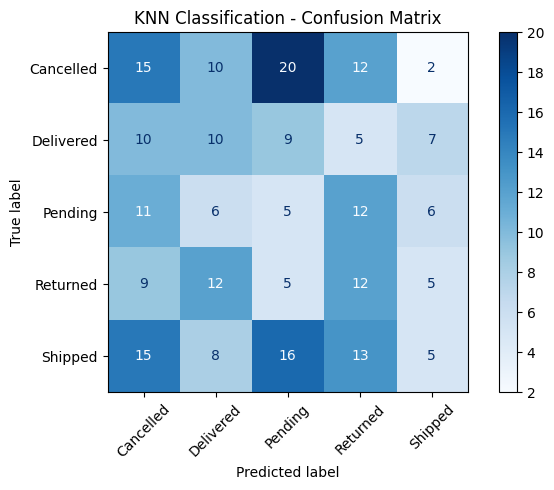

In [ ]:
#  Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred, labels=knn_pipeline.classes_)

plt.figure(figsize=(7, 5))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_pipeline.classes_)
display.plot(cmap="Blues", xticks_rotation=45, ax=plt.gca())
plt.title("KNN Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report
print("\nClassification Report:")


Classification Report:


In [13]:
# STEP 11: Predict a new order sample
print("\n--- INFERENCE ON A NEW ORDER ---")
new_order = pd.DataFrame([{
    "Product": "Laptop",
    "Quantity": 2,
    "UnitPrice": 500.0,
    "PaymentMethod": "Online",
    "ItemsInCart": 4,
    "CouponCode": "SAVE10",
    "ReferralSource": "Instagram",
    "TotalPrice": 1000.0,
    "OrderYear": 2025,
    "OrderMonth": 6,
    "OrderDay": 15,
    "DayOfWeek": 6
}])

prediction = knn_pipeline.predict(new_order)
print(f"Predicted Order Status: {prediction[0]}")
print("\nProject completed successfully!")


--- INFERENCE ON A NEW ORDER ---
Predicted Order Status: Pending

Project completed successfully!
